In [11]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("Data/sales_smoothing_datset.csv")
df

,Month,Sales
0,2023-01,120
1,2023-02,165
2,2023-03,110
3,2023-04,190
4,2023-05,145
5,2023-06,210
6,2023-07,130
7,2023-08,225
8,2023-09,160
9,2023-10,240


In [4]:
#Lambda function
new_fun = lambda x: x*x
new_fun(4)
#It replace the code below used in commercial code
# 
  #                     |||
   #                    |||
    #                   |||  
     #               \  |||  /
      #               \     /
       #               \   /
        #               \ / 

16

In [5]:
def add_one(x):
    x=x*x
    return(x)

In [6]:
add_one(4)

16

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Month   20 non-null     object
 1   Sales   20 non-null     int64 
dtypes: int64(1), object(1)
memory usage: 452.0+ bytes


In [8]:
#Converting the column into date time datatype
df["Month"] = pd.to_datetime(df["Month"])

#Setting the column as the index column
df.set_index("Month",inplace = True)

#Sorting the column 
df.sort_index(inplace=True)
df.head()


,Sales
Month,
2023-01-01,120
2023-02-01,165
2023-03-01,110
2023-04-01,190
2023-05-01,145


In [9]:
# A 3-month SMA calculates the avg of the latest three observation
df["SMA_3"] = df["Sales"].rolling(window=3).mean()
df.head(10)

,Sales,SMA_3
Month,,
2023-01-01,120,NaN
2023-02-01,165,NaN
2023-03-01,110,131.666667
2023-04-01,190,155.000000
2023-05-01,145,148.333333
2023-06-01,210,181.666667
2023-07-01,130,161.666667
2023-08-01,225,188.333333
2023-09-01,160,171.666667


In [13]:
df["SMA_4"] = df["Sales"].rolling(window=4).mean()
df.head(10)

,Sales,SMA_3,EMA,SMA_4
Month,,,,
2023-01-01,120,NaN,120.000000,NaN
2023-02-01,165,NaN,133.500000,NaN
2023-03-01,110,131.666667,126.450000,NaN
2023-04-01,190,155.000000,145.515000,146.25
2023-05-01,145,148.333333,145.360500,152.50
2023-06-01,210,181.666667,164.752350,163.75
2023-07-01,130,161.666667,154.326645,168.75
2023-08-01,225,188.333333,175.528651,177.50
2023-09-01,160,171.666667,170.870056,181.25


In [14]:
df["SMA_6"] = df["Sales"].rolling(window=6).mean()
df.head(10)

,Sales,SMA_3,EMA,SMA_4,SMA_6
Month,,,,,
2023-01-01,120,NaN,120.000000,NaN,NaN
2023-02-01,165,NaN,133.500000,NaN,NaN
2023-03-01,110,131.666667,126.450000,NaN,NaN
2023-04-01,190,155.000000,145.515000,146.25,NaN
2023-05-01,145,148.333333,145.360500,152.50,NaN
2023-06-01,210,181.666667,164.752350,163.75,156.666667
2023-07-01,130,161.666667,154.326645,168.75,158.333333
2023-08-01,225,188.333333,175.528651,177.50,168.333333
2023-09-01,160,171.666667,170.870056,181.25,176.666667


In [10]:
#Exponential Moving Average (EMA)

#Using a = 0.30
#adjust = False => Recursive Calculation
df["EMA"] = df["Sales"].ewm(alpha = 0.3, adjust = False).mean()

df.head()

,Sales,SMA_3,EMA
Month,,,
2023-01-01,120,NaN,120.0000
2023-02-01,165,NaN,133.5000
2023-03-01,110,131.666667,126.4500
2023-04-01,190,155.000000,145.5150
2023-05-01,145,148.333333,145.3605


<function matplotlib.pyplot.show(close=None, block=None)>

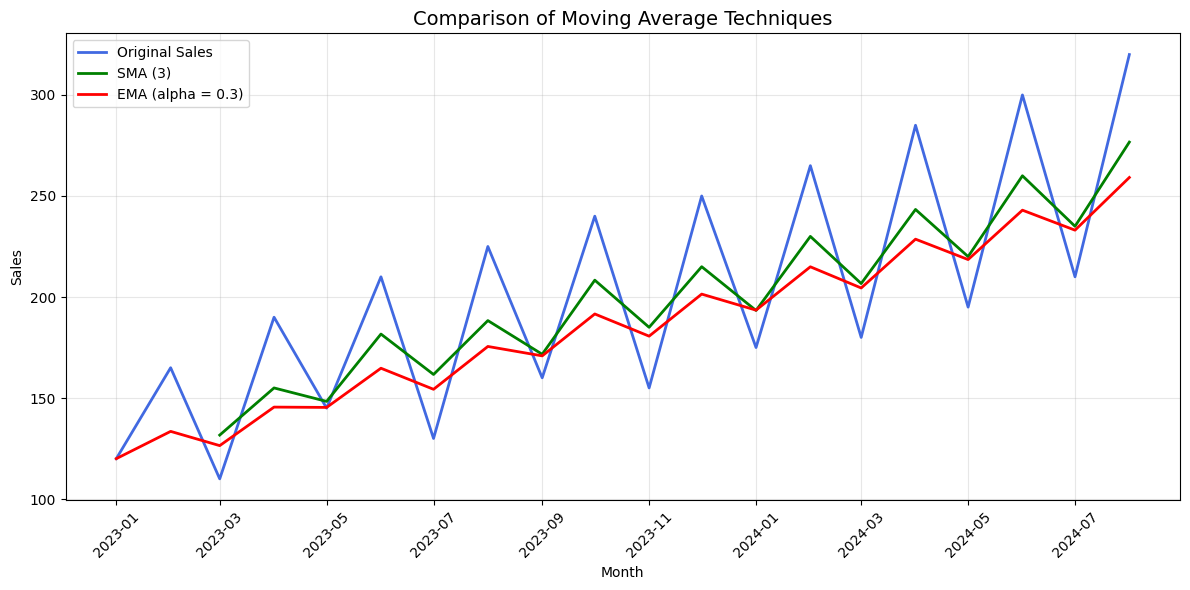

In [12]:
plt.figure(figsize = (12,6))
plt.plot(df.index, df["Sales"], color = "royalblue", linewidth = 2, label = "Original Sales")
plt.plot(df.index, df["SMA_3"], color = "green", linewidth = 2, label = "SMA (3)")
#plt.plot(df.index, df["WMA_3"], color = "orange", linewidth = 2, label = "WMA (3)")
plt.plot(df.index, df["EMA"], color = "red", linewidth = 2, label = "EMA (alpha = 0.3)")

plt.title("Comparison of Moving Average Techniques", fontsize = 14)
plt.xlabel("Month")
plt.ylabel("Sales")
plt.grid(alpha = 0.3)
plt.legend()
plt.xticks(rotation = 45)
plt.tight_layout()

plt.show

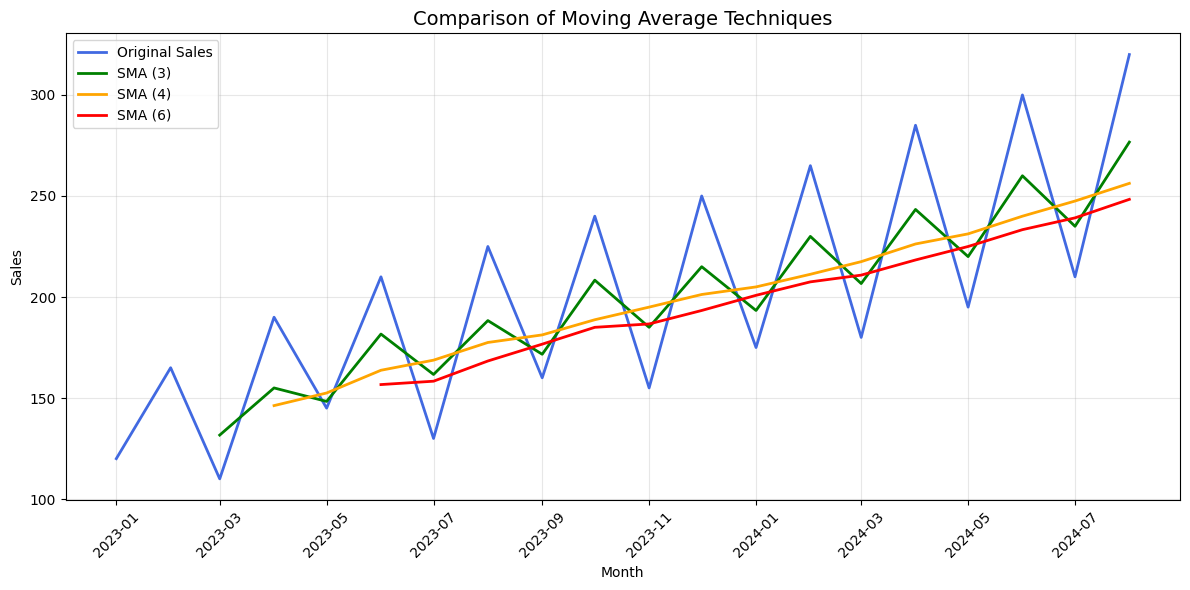

In [15]:
plt.figure(figsize = (12,6))
plt.plot(df.index, df["Sales"], color = "royalblue", linewidth = 2, label = "Original Sales")
plt.plot(df.index, df["SMA_3"], color = "green", linewidth = 2, label = "SMA (3)")
plt.plot(df.index, df["SMA_4"], color = "orange", linewidth = 2, label = "SMA (4) ")
plt.plot(df.index, df["SMA_6"], color = "red", linewidth = 2, label = "SMA (6)")

plt.title("Comparison of Moving Average Techniques", fontsize = 14)
plt.xlabel("Month")
plt.ylabel("Sales")
plt.grid(alpha = 0.3)
plt.legend()
plt.xticks(rotation = 45)
plt.tight_layout()